In [18]:
import random

import numpy as np

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

In [19]:
d = np.load("../data/embeddings.npz")
print(d.files)
for k in d.files:
    print(k, d[k].shape, d[k].dtype)

I, T, Y = d["I"], d["T"], d["Y"]

for name, X in [("I", I), ("T", T)]:
    print(f"{name}: has NaN = {np.isnan(X).any()}, has Inf = {np.isinf(X).any()}")

['T', 'I', 'Y']
T (2500, 512) float32
I (2500, 512) float32
Y (2500,) int64
I: has NaN = False, has Inf = False
T: has NaN = False, has Inf = False


In [20]:
from utils import load, center_normalize

# one fixed colour per modality, reused in every figure
COLOR_I = "#1f77b4"
COLOR_T = "#d95f02"
COLOR_HIGHLIGHT = "#c0392b"

# sanity check: the shared loader returns the same arrays as the cell above
I_, T_, Y_ = load()
assert np.array_equal(I_, I) and np.array_equal(T_, T) and np.array_equal(Y_, Y)

[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 34]
[103  73  63  93 103  49  49  81  86  68  82  62  80  72  75  81  73  84
  97  90  79  58  55 102  70  81  78  62  93 108 150]


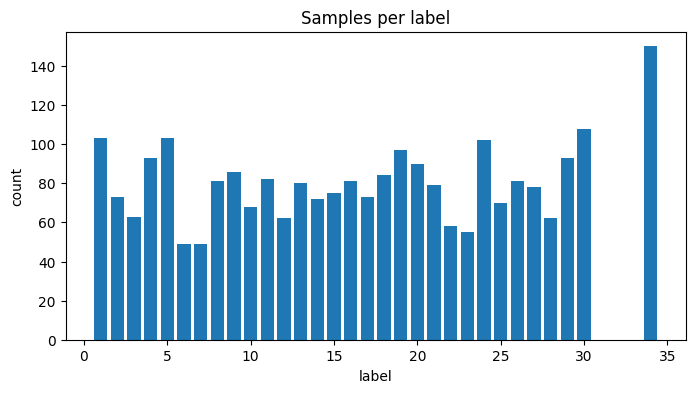

In [21]:
import matplotlib.pyplot as plt

labels, counts = np.unique(Y, return_counts=True)
print(labels)
print(counts)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(labels, counts)
ax.set_xlabel("label")
ax.set_ylabel("count")
ax.set_title("Samples per label")
plt.show()

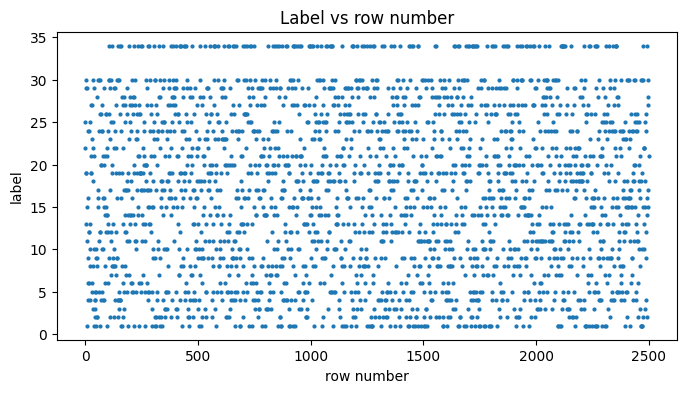

In [22]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(np.arange(len(Y)), Y, s=4)
ax.set_xlabel("row number")
ax.set_ylabel("label")
ax.set_title("Label vs row number")
plt.show()

I: norm min=8.8634 mean=10.1945 max=12.4271 std=0.4643
T: norm min=6.3408 mean=9.0590 max=12.2875 std=0.8620


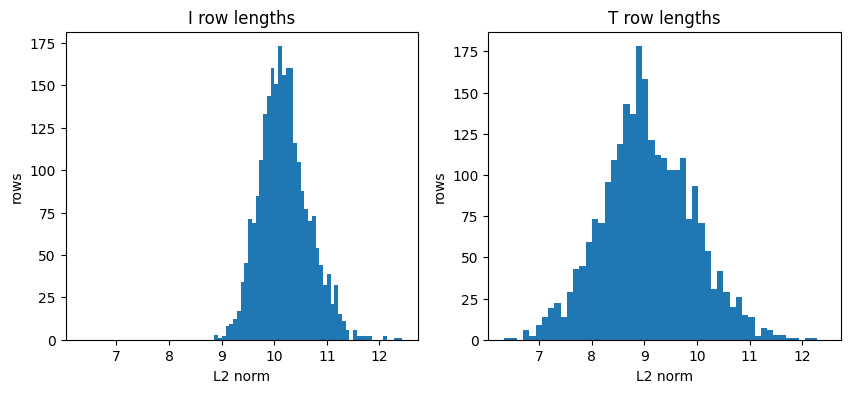

In [23]:
arrays = {"I": I, "T": T}

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True)
for ax, (name, X) in zip(axes, arrays.items()):
    norms = np.linalg.norm(X, axis=1)
    print(f"{name}: norm min={norms.min():.4f} mean={norms.mean():.4f} max={norms.max():.4f} std={norms.std():.4f}")
    ax.hist(norms, bins=50)
    ax.set_title(f"{name} row lengths")
    ax.set_xlabel("L2 norm")
    ax.set_ylabel("rows")
plt.show()

I: min=-9.9753 max=3.5370 mean=-0.0129 std=0.4508
T: min=-3.7179 max=7.6690 mean=0.0091 std=0.4021


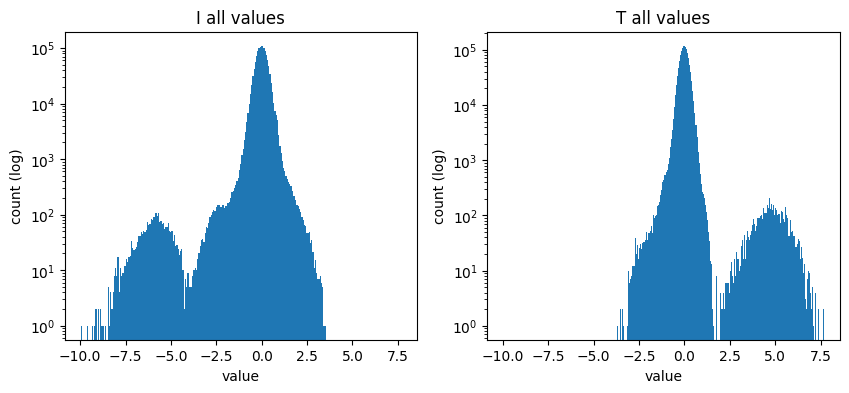

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True)
arrays = {"I": I, "T": T}

for ax, (name, X) in zip(axes, arrays.items()):
    v = X.ravel()
    print(f"{name}: min={v.min():.4f} max={v.max():.4f} mean={v.mean():.4f} std={v.std():.4f}")
    ax.hist(v, bins=200)
    ax.set_yscale("log")
    ax.set_title(f"{name} all values")
    ax.set_xlabel("value")
    ax.set_ylabel("count (log)")
plt.show()

I: col mean range [-5.9228, 1.5018], col std range [0.0725, 0.8743]
T: col mean range [-1.3422, 4.7615], col std range [0.1174, 0.8732]


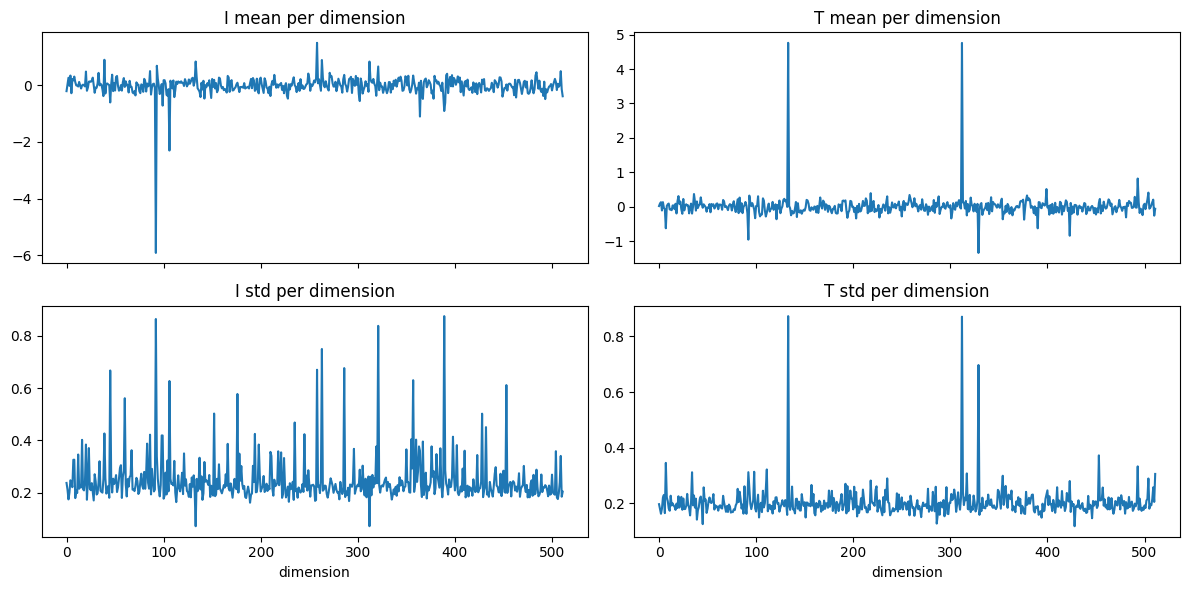

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
for col, (name, X) in enumerate(arrays.items()):
    mean, std = X.mean(0), X.std(0)
    print(f"{name}: col mean range [{mean.min():.4f}, {mean.max():.4f}], col std range [{std.min():.4f}, {std.max():.4f}]")
    axes[0, col].plot(mean)
    axes[0, col].set_title(f"{name} mean per dimension")
    axes[1, col].plot(std)
    axes[1, col].set_title(f"{name} std per dimension")
    axes[1, col].set_xlabel("dimension")
plt.tight_layout()
plt.show()

A few dimensions carry large constant offsets (I: dims 92 and 106; T: dims 133 and 312), which inflate cosine similarity between all rows; therefore we subtract the column mean before normalising.

In [26]:
for name, X in arrays.items():
    mean = X.mean(0)
    top = np.argsort(-np.abs(mean))[:3]
    print(f"{name}: top-3 dimensions by |mean|")
    for k in top:
        print(f"  dim {k:3d}: mean={mean[k]:+.4f}")

I: top-3 dimensions by |mean|
  dim  92: mean=-5.9228
  dim 106: mean=-2.3047
  dim 258: mean=+1.5018
T: top-3 dimensions by |mean|
  dim 133: mean=+4.7615
  dim 312: mean=+4.7583
  dim 329: mean=-1.3422


In [27]:
for name, X in arrays.items():
    n_unique = len(np.unique(X, axis=0))
    print(f"{name}: {len(X)} rows, {n_unique} unique, {len(X) - n_unique} duplicate rows")

# rows of T that also appear somewhere in I
I_rows = {row.tobytes() for row in I}
shared = sum(row.tobytes() in I_rows for row in T)
print(f"T rows that also appear in I: {shared}")

I: 2500 rows, 2500 unique, 0 duplicate rows
T: 2500 rows, 2075 unique, 425 duplicate rows
T rows that also appear in I: 0


group size -> number of groups
    1 -> 1902
    2 -> 95
    3 -> 32
    4 -> 17
    5 -> 7
    6 -> 4
    7 -> 4
    8 -> 2
    9 -> 6
   10 -> 2
   12 -> 2
   13 -> 1
   30 -> 1
groups with more than one row: 173 (largest: 30)


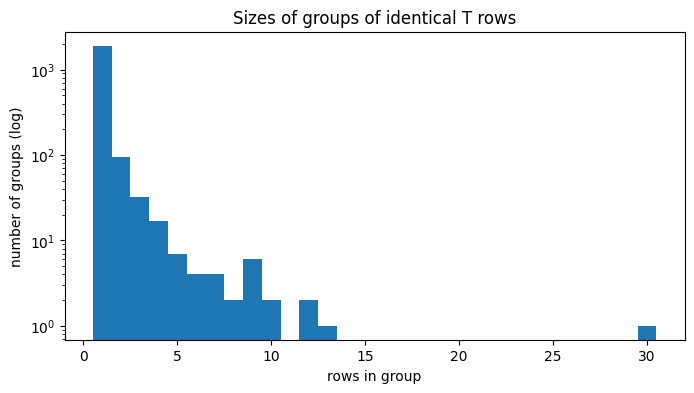

In [28]:
_, inv, cnt = np.unique(T, axis=0, return_inverse=True, return_counts=True)
inv = inv.ravel()

sizes, n_groups = np.unique(cnt, return_counts=True)
print("group size -> number of groups")
for s, n in zip(sizes, n_groups):
    print(f"  {s:3d} -> {n}")
print(f"groups with more than one row: {(cnt > 1).sum()} (largest: {cnt.max()})")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(cnt, bins=np.arange(1, cnt.max() + 2) - 0.5)
ax.set_yscale("log")
ax.set_xlabel("rows in group")
ax.set_ylabel("number of groups (log)")
ax.set_title("Sizes of groups of identical T rows")
plt.show()

In [29]:
dup_groups = np.flatnonzero(cnt > 1)
n_labels = np.array([len(np.unique(Y[inv == g])) for g in dup_groups])

print(f"duplicate groups: {len(dup_groups)}")
print(f"  single label: {(n_labels == 1).sum()}")
print(f"  mixed labels: {(n_labels > 1).sum()}")

for g in dup_groups[n_labels > 1]:
    rows = np.flatnonzero(inv == g)
    lab, c = np.unique(Y[rows], return_counts=True)
    print(f"group {g}: {len(rows)} rows, rows {rows.tolist()}, labels {dict(zip(lab.tolist(), c.tolist()))}")

duplicate groups: 173
  single label: 171
  mixed labels: 2
group 1306: 2 rows, rows [374, 1363], labels {21: 1, 22: 1}
group 1618: 2 rows, rows [287, 1934], labels {13: 1, 15: 1}


matching pairs: mean=0.2781 std=0.0285
random pairs:   mean=0.2211 std=0.0327


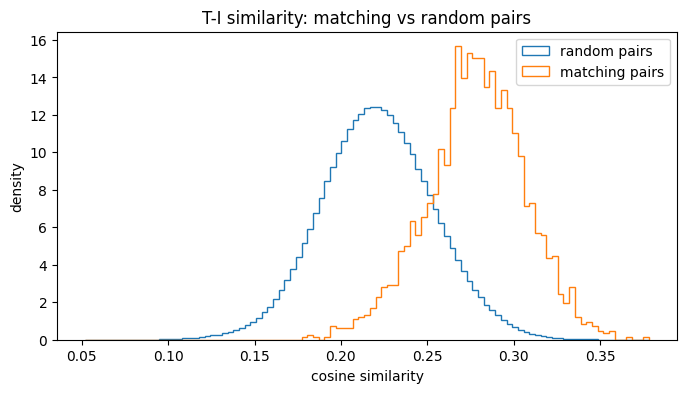

In [30]:
In = I / np.linalg.norm(I, axis=1, keepdims=True)
Tn = T / np.linalg.norm(T, axis=1, keepdims=True)

S = Tn @ In.T  # S[i, j] = cosine similarity between T row i and I row j
n = len(S)

matching = np.diag(S)
random_pairs = S[~np.eye(n, dtype=bool)]
print(f"matching pairs: mean={matching.mean():.4f} std={matching.std():.4f}")
print(f"random pairs:   mean={random_pairs.mean():.4f} std={random_pairs.std():.4f}")

bins = np.linspace(S.min(), S.max(), 100)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(random_pairs, bins=bins, density=True, histtype="step", label="random pairs")
ax.hist(matching, bins=bins, density=True, histtype="step", label="matching pairs")
ax.set_xlabel("cosine similarity")
ax.set_ylabel("density")
ax.set_title("T-I similarity: matching vs random pairs")
ax.legend()
plt.show()

                       raw  centered
matching mean       0.2781    0.1853
matching std        0.0285    0.0886
random mean         0.2211    0.0000
random std          0.0327    0.0808


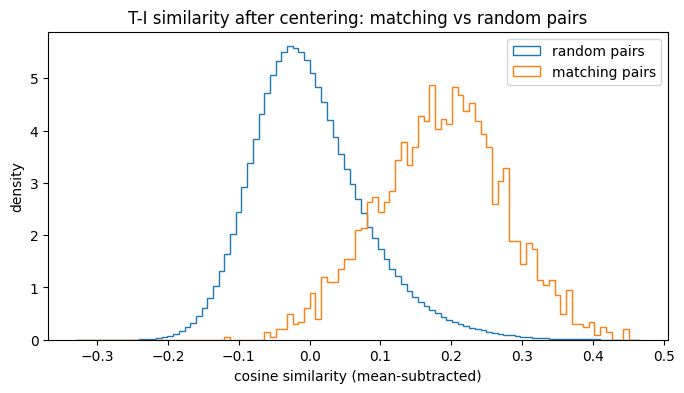

In [31]:
Ic, Tc = center_normalize(I), center_normalize(T)
Sc = Tc @ Ic.T

match_c = np.diag(Sc)
rand_c = Sc[~np.eye(n, dtype=bool)]

print(f"{'':16s}{'raw':>10s}{'centered':>10s}")
print(f"{'matching mean':16s}{matching.mean():10.4f}{match_c.mean():10.4f}")
print(f"{'matching std':16s}{matching.std():10.4f}{match_c.std():10.4f}")
print(f"{'random mean':16s}{random_pairs.mean():10.4f}{rand_c.mean():10.4f}")
print(f"{'random std':16s}{random_pairs.std():10.4f}{rand_c.std():10.4f}")

bins_c = np.linspace(Sc.min(), Sc.max(), 100)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(rand_c, bins=bins_c, density=True, histtype="step", label="random pairs")
ax.hist(match_c, bins=bins_c, density=True, histtype="step", label="matching pairs")
ax.set_xlabel("cosine similarity (mean-subtracted)")
ax.set_ylabel("density")
ax.set_title("T-I similarity after centering: matching vs random pairs")
ax.legend()
plt.show()

In [32]:
same = Y[:, None] == Y[None, :]
off_diag = ~np.eye(n, dtype=bool)

for name, Xn in [("I", In), ("T", Tn)]:
    Sxx = Xn @ Xn.T
    same_sim = Sxx[same & off_diag].mean()
    diff_sim = Sxx[~same].mean()
    print(f"{name}: same label mean={same_sim:.4f}, different label mean={diff_sim:.4f}, gap={same_sim - diff_sim:.4f}")

I: same label mean=0.8086, different label mean=0.6537, gap=0.1548
T: same label mean=0.8152, different label mean=0.7246, gap=0.0906


In [33]:
label_gap = {}
print(f"{'':4s}{'':10s}{'same':>9s}{'different':>11s}{'gap':>9s}")
for name, Xraw, Xc in [("I", In, Ic), ("T", Tn, Tc)]:
    label_gap[name] = {}
    for tag, X in [("raw", Xraw), ("centered", Xc)]:
        Sxx = X @ X.T
        same_sim, diff_sim = Sxx[same & off_diag].mean(), Sxx[~same].mean()
        label_gap[name][tag] = dict(same=same_sim, diff=diff_sim, gap=same_sim - diff_sim)
        print(f"{name:4s}{tag:10s}{same_sim:9.4f}{diff_sim:11.4f}{same_sim - diff_sim:9.4f}")

                   same  different      gap
I   raw          0.8086     0.6537   0.1548
I   centered     0.4342    -0.0153   0.4496
T   raw          0.8152     0.7246   0.0906
T   centered     0.3287    -0.0106   0.3393


In [34]:
best_I = S.argmax(axis=1)  # most similar I row for each T row
top1 = (best_I == np.arange(n)).mean()
print(f"top-1 retrieval: {top1:.4f} ({(best_I == np.arange(n)).sum()} of {n}), chance = {1 / n:.4f}")

top-1 retrieval: 0.0208 (52 of 2500), chance = 0.0004


In [35]:
def topk_hits(S_, k):
    top = np.argsort(-S_, axis=1)[:, :k]
    return (top == np.arange(len(S_))[:, None]).any(axis=1).mean()

retrieval = {tag: {k: topk_hits(S_, k) for k in (1, 5)} for tag, S_ in [("raw", S), ("centered", Sc)]}

print(f"chance: top-1 = {1 / n:.4f}, top-5 = {5 / n:.4f}")
print(f"{'':10s}{'top-1':>9s}{'top-5':>9s}")
for tag, r in retrieval.items():
    print(f"{tag:10s}{r[1]:9.4f}{r[5]:9.4f}")

chance: top-1 = 0.0004, top-5 = 0.0020
              top-1    top-5
raw          0.0208   0.0728
centered     0.0272   0.0804


I: adjacent mean=0.6579 std=0.0788 | random mean=0.6591 std=0.0791
T: adjacent mean=0.7253 std=0.0824 | random mean=0.7278 std=0.0810


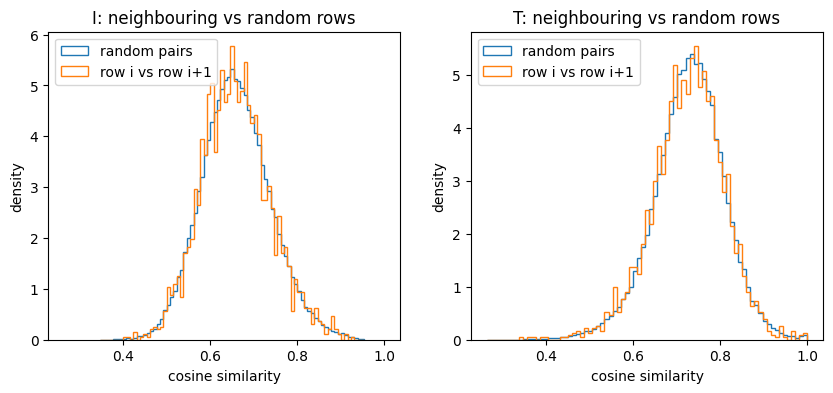

In [36]:
rng = np.random.default_rng(SEED)

normed = {"I": In, "T": Tn}
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True)
for ax, (name, Xn) in zip(axes, normed.items()):
    adjacent = (Xn[:-1] * Xn[1:]).sum(axis=1)  # cosine of row i and row i+1

    a = rng.integers(0, n, size=100_000)
    b = rng.integers(0, n, size=100_000)
    keep = a != b
    random_sim = (Xn[a[keep]] * Xn[b[keep]]).sum(axis=1)

    print(f"{name}: adjacent mean={adjacent.mean():.4f} std={adjacent.std():.4f} | "
          f"random mean={random_sim.mean():.4f} std={random_sim.std():.4f}")

    bins = np.linspace(min(adjacent.min(), random_sim.min()), max(adjacent.max(), random_sim.max()), 80)
    ax.hist(random_sim, bins=bins, density=True, histtype="step", label="random pairs")
    ax.hist(adjacent, bins=bins, density=True, histtype="step", label="row i vs row i+1")
    ax.set_title(f"{name}: neighbouring vs random rows")
    ax.set_xlabel("cosine similarity")
    ax.set_ylabel("density")
    ax.legend()
plt.show()

In [37]:
rng_c = np.random.default_rng(SEED)
a = rng_c.integers(0, n, size=100_000)
b = rng_c.integers(0, n, size=100_000)
keep = a != b
a, b = a[keep], b[keep]

adjacency = {}
print(f"{'':4s}{'':10s}{'adjacent':>10s}{'random':>10s}")
for name, Xraw, Xc in [("I", In, Ic), ("T", Tn, Tc)]:
    adjacency[name] = {}
    for tag, X in [("raw", Xraw), ("centered", Xc)]:
        adj = (X[:-1] * X[1:]).sum(axis=1).mean()
        rnd = (X[a] * X[b]).sum(axis=1).mean()
        adjacency[name][tag] = dict(adjacent=adj, random=rnd)
        print(f"{name:4s}{tag:10s}{adj:10.4f}{rnd:10.4f}")

                adjacent    random
I   raw           0.6579    0.6591
I   centered     -0.0037    0.0001
T   raw           0.7253    0.7279
T   centered     -0.0073    0.0011


## Fig 1: Dataset overview

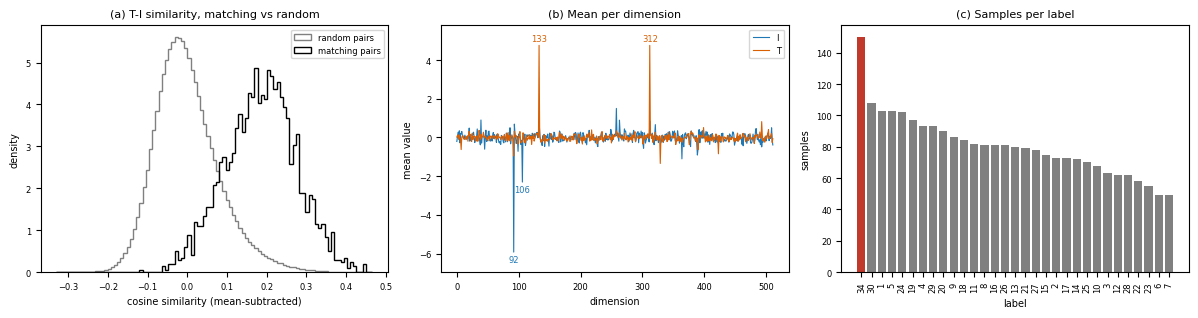

In [38]:
from pathlib import Path

fig_dir = Path("../figures")
fig_dir.mkdir(exist_ok=True)

with plt.rc_context({"font.size": 7, "axes.titlesize": 8, "axes.labelsize": 7,
                     "xtick.labelsize": 6, "ytick.labelsize": 6, "legend.fontsize": 6}):
    fig, (ax_a, ax_b, ax_c) = plt.subplots(1, 3, figsize=(12, 3.2))

    # (a) matching vs random T-I similarity, mean-subtracted
    ax_a.hist(rand_c, bins=bins_c, density=True, histtype="step", color="gray", label="random pairs")
    ax_a.hist(match_c, bins=bins_c, density=True, histtype="step", color="black", label="matching pairs")
    ax_a.set_xlabel("cosine similarity (mean-subtracted)")
    ax_a.set_ylabel("density")
    ax_a.set_title("(a) T-I similarity, matching vs random")
    ax_a.legend()

    # (b) mean per dimension, outliers annotated
    for name, X, color in [("I", I, COLOR_I), ("T", T, COLOR_T)]:
        mean = X.mean(0)
        ax_b.plot(mean, color=color, lw=0.8, label=name)
        for k in np.flatnonzero(np.abs(mean) > 2):
            above = mean[k] > 0
            ax_b.annotate(str(k), (k, mean[k]), color=color, fontsize=6, ha="center",
                          va="bottom" if above else "top",
                          xytext=(0, 2 if above else -2), textcoords="offset points")
    ax_b.set_xlabel("dimension")
    ax_b.set_ylabel("mean value")
    ax_b.set_title("(b) Mean per dimension")
    ax_b.set_ylim(ax_b.get_ylim()[0] - 0.5, ax_b.get_ylim()[1] + 0.5)
    ax_b.legend()

    # (c) samples per label, sorted by count, label 34 highlighted
    lab, cts = np.unique(Y, return_counts=True)
    order = np.argsort(-cts, kind="stable")
    lab, cts = lab[order], cts[order]
    ax_c.bar(np.arange(len(lab)), cts, color=[COLOR_HIGHLIGHT if l == 34 else "gray" for l in lab])
    ax_c.set_xticks(np.arange(len(lab)))
    ax_c.set_xticklabels(lab, rotation=90)
    ax_c.set_xlabel("label")
    ax_c.set_ylabel("samples")
    ax_c.set_title("(c) Samples per label")

    plt.tight_layout()
    fig.savefig(fig_dir / "fig1_overview.pdf", bbox_inches="tight")
    fig.savefig(fig_dir / "fig1_overview.png", dpi=200, bbox_inches="tight")
    plt.show()

## Summary

In [39]:
import json

labels_present = np.unique(Y)
summary = {
    "n_samples": int(len(Y)),
    "n_classes": int(len(labels_present)),
    "missing_labels": [int(l) for l in range(Y.min(), Y.max() + 1) if l not in labels_present],
    "label_34_count": int((Y == 34).sum()),
    "n_unique_T_rows": int(len(cnt)),
    "n_duplicate_groups": int((cnt > 1).sum()),
    "groups_with_mixed_labels": int((n_labels > 1).sum()),
    "cosine_matching_raw": round(float(matching.mean()), 4),
    "cosine_random_raw": round(float(random_pairs.mean()), 4),
    "cosine_matching_centered": round(float(match_c.mean()), 4),
    "cosine_random_centered": round(float(rand_c.mean()), 4),
    "label_gap_I_raw": round(float(label_gap["I"]["raw"]["gap"]), 4),
    "label_gap_I_centered": round(float(label_gap["I"]["centered"]["gap"]), 4),
    "label_gap_T_raw": round(float(label_gap["T"]["raw"]["gap"]), 4),
    "label_gap_T_centered": round(float(label_gap["T"]["centered"]["gap"]), 4),
    "top1_raw": round(float(retrieval["raw"][1]), 4),
    "top5_raw": round(float(retrieval["raw"][5]), 4),
    "top1_centered": round(float(retrieval["centered"][1]), 4),
    "top5_centered": round(float(retrieval["centered"][5]), 4),
}
print(json.dumps(summary, indent=2))

{
  "n_samples": 2500,
  "n_classes": 31,
  "missing_labels": [
    31,
    32,
    33
  ],
  "label_34_count": 150,
  "n_unique_T_rows": 2075,
  "n_duplicate_groups": 173,
  "groups_with_mixed_labels": 2,
  "cosine_matching_raw": 0.2781,
  "cosine_random_raw": 0.2211,
  "cosine_matching_centered": 0.1853,
  "cosine_random_centered": 0.0,
  "label_gap_I_raw": 0.1548,
  "label_gap_I_centered": 0.4496,
  "label_gap_T_raw": 0.0906,
  "label_gap_T_centered": 0.3393,
  "top1_raw": 0.0208,
  "top5_raw": 0.0728,
  "top1_centered": 0.0272,
  "top5_centered": 0.0804
}
